# LAB08 - Pretrained BERT fine-tuning

Mục tiêu: so sánh pretrained/random-init với cùng kiến trúc; frozen/full tuning; data efficiency; sequence length; IMDb -> Yelp; confidence. Đọc prediction.md trước kết quả. Sinh viên tự phân tích/reflection theo W8 mục 24.

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import torch
ROOT=Path.cwd() if (Path.cwd()/"pretrained_classification.py").exists() else Path.cwd()/"lab8"
assert (ROOT/"model/config.json").exists()
sys.path.insert(0,str(ROOT))
from pretrained_classification import get_tokenizer, load_classifier
torch.set_num_threads(4)
tokenizer=get_tokenizer()
print("Tokenizer:",type(tokenizer).__name__,"vocab:",len(tokenizer))
environment=json.loads((ROOT/"environment.json").read_text(encoding="utf-8"))
print(json.dumps(environment,ensure_ascii=False,indent=2))


Tokenizer: BertTokenizer vocab: 30522
{
  "started_utc": "2026-11-04T17:48:30.293996+00:00",
  "seed": 42,
  "model_id": "google/bert_uncased_L-2_H-128_A-2",
  "tokenizer": "BertTokenizerFast / uncased WordPiece",
  "torch": "2.15.0.dev20260907+cu126",
  "transformers": "5.19.0",
  "python": "3.14.8",
  "numpy": "2.5.3",
  "device": "cuda",
  "hardware": "NVIDIA GeForce RTX 4060 Laptop GPU",
  "train_validation_test": [
    20000,
    5000,
    25000
  ],
  "epochs": 4,
  "batch_size": 64,
  "optimizer": "AdamW",
  "lr": 0.0001,
  "weight_decay": 0.01,
  "gradient_clip": 1.0,
  "scheduler": null,
  "primary": "pretrained_finetune_p100_t128; fixed before experiments",
  "checkpoint_selection": "minimum validation cross entropy per run",
  "timing": "summed train epochs only; CUDA synchronized; validation/test excluded; frozen includes encoder forward each batch, no feature cache",
  "max_length_definition": "total WordPiece tokens including CLS and SEP",
  "determinism": "fixed seeds an

## Kế hoạch và controls

11 run × 4 epoch, seed42, batch64, AdamW1e-4, weight_decay0.01. Pretrained/scratch dùng cùng tokenizer, BERT config và nested subsets 10/25/50/100%; cố định validation/test. Primary là pretrained100%/T128, không chọn theo test. Giữ LR chung để kiểm soát, chưa tune từng mode.

In [2]:
from pretrained_classification import BertSentimentClassifier
import inspect
print(inspect.getsource(BertSentimentClassifier))


class BertSentimentClassifier(nn.Module):
    def __init__(self,initialization='pretrained',frozen=False):
        super().__init__()
        config=AutoConfig.from_pretrained(str(ROOT/'model'),local_files_only=True)
        if initialization=='pretrained':
            self.encoder=AutoModel.from_pretrained(str(ROOT/'model'),local_files_only=True,
                                                   add_pooling_layer=False)
        elif initialization=='scratch':
            self.encoder=AutoModel.from_config(config,add_pooling_layer=False)
        else:
            raise ValueError('initialization must be pretrained or scratch')
        self.frozen=frozen
        for p in self.encoder.parameters():p.requires_grad_(not frozen)
        self.dropout=nn.Dropout(config.hidden_dropout_prob)
        self.classifier=nn.Linear(config.hidden_size,2)

    def train(self,mode=True):
        super().train(mode)
        # Frozen features should not be randomized by encoder dropout.
        if self.fr

## Training

Mặc định dùng kết quả thật đã lưu. Đặt RUN_TRAINING=True để train lại toàn bộ; sau đó gọi make_reports.py từ terminal để cập nhật báo cáo/hình.

In [3]:
RUN_TRAINING=False
if RUN_TRAINING:
    import subprocess
    subprocess.run([sys.executable,"-u",str(ROOT/"run_experiments.py")],check=True)
else:
    print("Đọc 11 run đã lưu; không train lại trong phiên review.")
rows=list(csv.DictReader((ROOT/"results.csv").open(encoding="utf-8")))
assert len(rows)==11
def show(selected,cols):
    print(" | ".join(cols))
    for r in selected: print(" | ".join(str(r[c]) for c in cols))


Đọc 11 run đã lưu; không train lại trong phiên review.


## Kiểm tra split và truncation

Cắt tensor cache phải phục hồi SEP tại boundary; đối chiếu với tokenizer trực tiếp. Training subsets lồng nhau, chỉ chứa training indices.

In [4]:
from run_experiments import encode,loader
splits=json.loads((ROOT/"split_indices.json").read_text())
assert not set(splits["train"]).intersection(splits["validation"])
if (ROOT.parent/"lab7/split_indices.json").exists():
    previous=json.loads((ROOT.parent/"lab7/split_indices.json").read_text())
    assert splits["train"]==previous["train"] and splits["validation"]==previous["validation"]
subsets=splits["nested_subsets_local"]
for a,b in [("0.1","0.25"),("0.25","0.5"),("0.5","1.0")]:
    assert set(subsets[a]).issubset(subsets[b])
examples=["A good movie.","The actors played their parts well. "*100]
cached=encode(examples,tokenizer)
for length in [64,128,256]:
    ids,mask,types,y=next(iter(loader(cached,np.array([1,1]),length,2,tokenizer)))
    direct=tokenizer(examples,padding="max_length",truncation=True,max_length=length,return_tensors="pt")
    assert torch.equal(ids,direct["input_ids"])
    assert torch.equal(mask,direct["attention_mask"])
print("PASS: disjoint/nested splits, LAB7 split equality, SEP-safe truncation at 64/128/256")


PASS: disjoint/nested splits, LAB7 split equality, SEP-safe truncation at 64/128/256


## Experiment 1-2: initialization và frozen encoder

In [5]:
selected=[r for r in rows if r["fraction"]=="1.0" and r["max_length"]=="128"]
show(selected,["initialization","mode","parameters","trainable_parameters","accuracy","precision","recall","f1","train_seconds"])
frozen=json.loads((ROOT/"frozen_verification.json").read_text())
assert frozen["max_encoder_parameter_change"]==0 and frozen["encoder_trainable_parameters"]==0
print("Frozen verification:",frozen)


initialization | mode | parameters | trainable_parameters | accuracy | precision | recall | f1 | train_seconds
pretrained | finetune | 4369666 | 4369666 | 0.81692 | 0.8099037784557616 | 0.82824 | 0.8189692678875133 | 35.42873770010192
scratch | finetune | 4369666 | 4369666 | 0.81612 | 0.817109381269561 | 0.81456 | 0.8158326990104563 | 34.997425200010184
pretrained | frozen | 4369666 | 258 | 0.67552 | 0.6923211781206171 | 0.63184 | 0.6606993474987451 | 14.805737299961038
Frozen verification: {'max_encoder_parameter_change': 0.0, 'encoder_trainable_parameters': 0, 'head_trainable_parameters': 258}


## Experiment 3: data efficiency

Xem cả accuracy và F1: một classifier thiên một lớp có thể F1 positive tương đối cao dù accuracy thấp. Các run không tiếp tục train từ subset nhỏ.

In [6]:
data=[r for r in rows if r["mode"]=="finetune" and r["max_length"]=="128"]
show(data,["initialization","fraction","train_samples","accuracy","f1"])


initialization | fraction | train_samples | accuracy | f1
pretrained | 0.1 | 2000 | 0.73932 | 0.7411320754716981
pretrained | 0.25 | 5000 | 0.7786 | 0.7647583832717073
pretrained | 0.5 | 10000 | 0.7962 | 0.8002195820099596
pretrained | 1.0 | 20000 | 0.81692 | 0.8189692678875133
scratch | 0.1 | 2000 | 0.54292 | 0.6829268292682927
scratch | 0.25 | 5000 | 0.73396 | 0.6803172314347513
scratch | 0.5 | 10000 | 0.80236 | 0.798942014242116
scratch | 1.0 | 20000 | 0.81612 | 0.8158326990104563


Accuracy và F1 theo phần trăm dữ liệu downstream

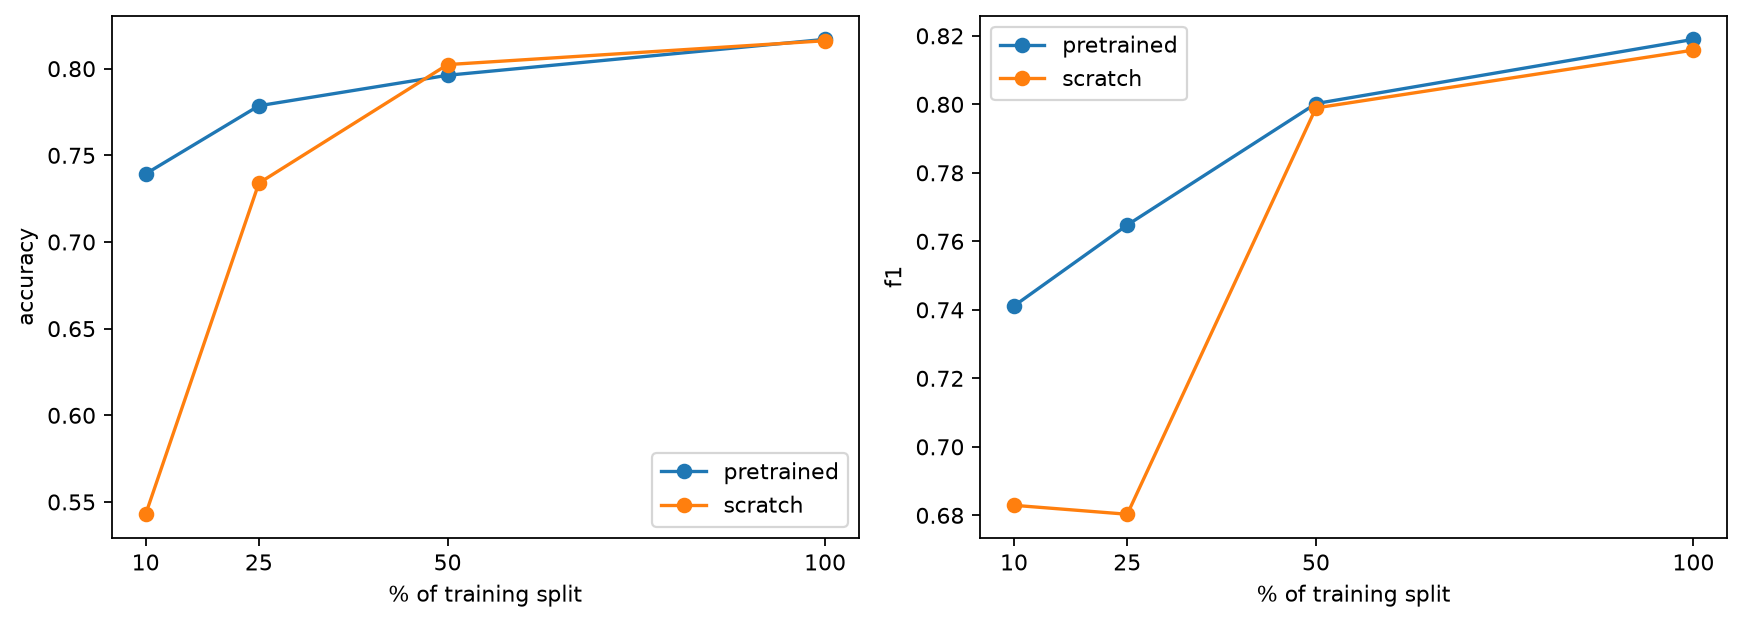

## Experiment 4: sequence length

T gồm CLS/SEP. Memory là peak PyTorch allocated; không phải toàn GPU memory. SDPA backend có thể tối ưu lưu trữ tensor attention.

In [7]:
lengths=[r for r in rows if r["initialization"]=="pretrained" and r["mode"]=="finetune" and r["fraction"]=="1.0"]
show(lengths,["max_length","accuracy","f1","train_seconds","peak_allocated_MiB"])


max_length | accuracy | f1 | train_seconds | peak_allocated_MiB
128 | 0.81692 | 0.8189692678875133 | 35.42873770010192 | 222.95751953125
64 | 0.76384 | 0.7608748481166464 | 26.042540200054646 | 138.67626953125
256 | 0.84592 | 0.8433636955107352 | 61.935386900033336 | 411.39599609375


Train và validation loss của 11 run

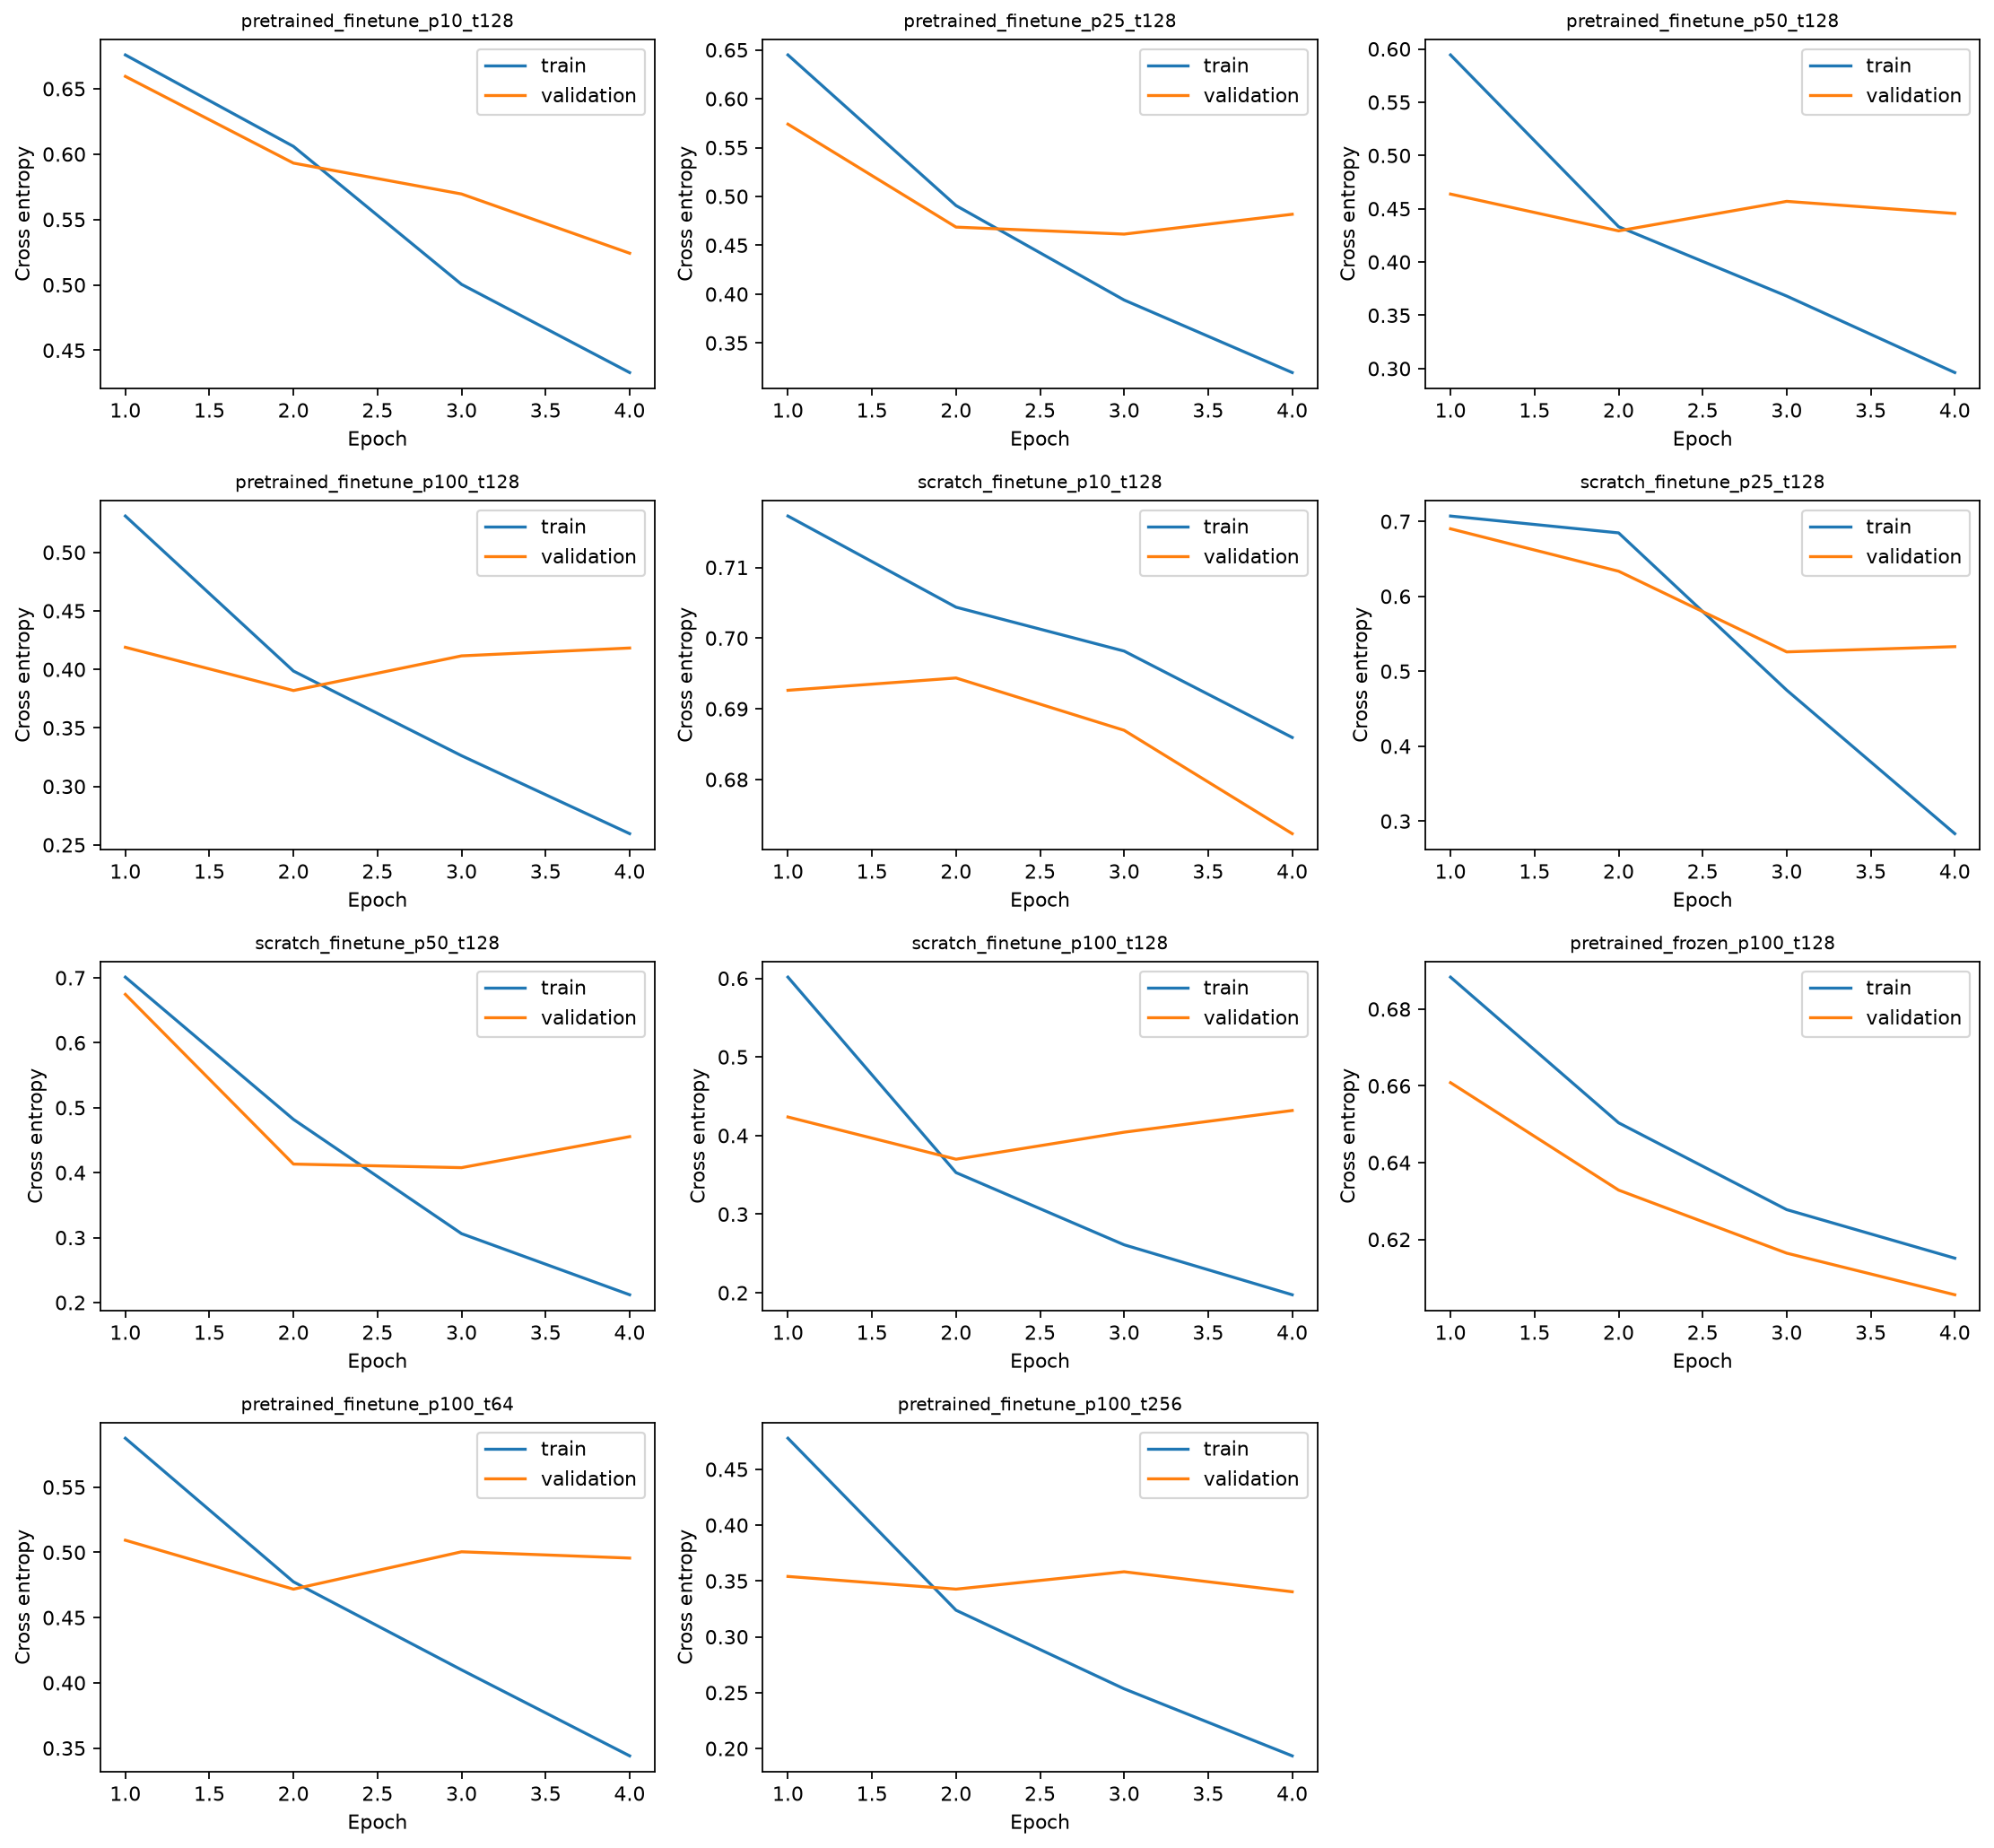

## Experiment 5: domain shift

Train IMDb; evaluate official IMDb test và 4000 mẫu Yelp official test cố định. Không fine-tune/tune trên Yelp. Chênh lệch còn gồm style, độ dài, labeling; không xem đó là đo catastrophic forgetting.

In [8]:
domains=json.loads((ROOT/"domain_results.json").read_text())
show(domains,["domain","n","accuracy","precision","recall","f1"])


domain | n | accuracy | precision | recall | f1
IMDb movie reviews | 25000 | 0.81692 | 0.8099037784557616 | 0.82824 | 0.8189692678875133
Yelp business reviews | 4000 | 0.791 | 0.7482935153583617 | 0.877 | 0.8075506445672191


Confusion matrix primary model trên IMDb test

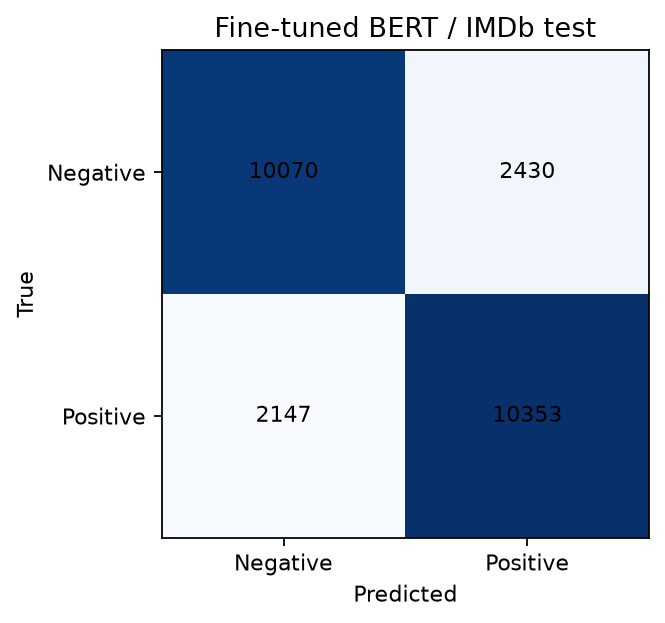

## Confidence

Low [0.5,0.7), medium [0.7,0.9), high [0.9,1]; threshold định trước. Max softmax không phải bảo đảm prediction đúng hay probability đã calibration.

In [9]:
buckets=json.loads((ROOT/"confidence_buckets.json").read_text())
show(buckets,["bucket","n","errors","mean_confidence","accuracy"])
errors=json.loads((ROOT/"error_examples.json").read_text())
assert sum(e["selection"]=="false_positive" for e in errors)==3
assert sum(e["selection"]=="false_negative" for e in errors)==3
assert sum(e["selection"]=="most_confident_wrong" for e in errors)==2
for e in errors: print("test",e["test_index"],e["selection"],"true",e["true"],"pred",e["pred"],"confidence",round(e["confidence"],6),"truncated",e["truncated"])


bucket | n | errors | mean_confidence | accuracy
low_0.50_0.70 | 4896 | 1991 | 0.602687656879425 | 0.5933415032679739
medium_0.70_0.90 | 7396 | 1846 | 0.8123235702514648 | 0.7504056246619795
high_0.90_1.00 | 12708 | 740 | 0.9624242186546326 | 0.941768964431854
test 4 false_positive true 0 pred 1 confidence 0.933758 truncated True
test 6 false_positive true 0 pred 1 confidence 0.976569 truncated True
test 17 false_positive true 0 pred 1 confidence 0.575591 truncated True
test 12512 false_negative true 1 pred 0 confidence 0.667338 truncated True
test 12518 false_negative true 1 pred 0 confidence 0.544277 truncated False
test 12525 false_negative true 1 pred 0 confidence 0.944682 truncated True
test 4118 most_confident_wrong true 0 pred 1 confidence 0.996477 truncated False
test 19650 most_confident_wrong true 1 pred 0 confidence 0.994434 truncated True


Confidence buckets và phân phối prediction đúng/sai

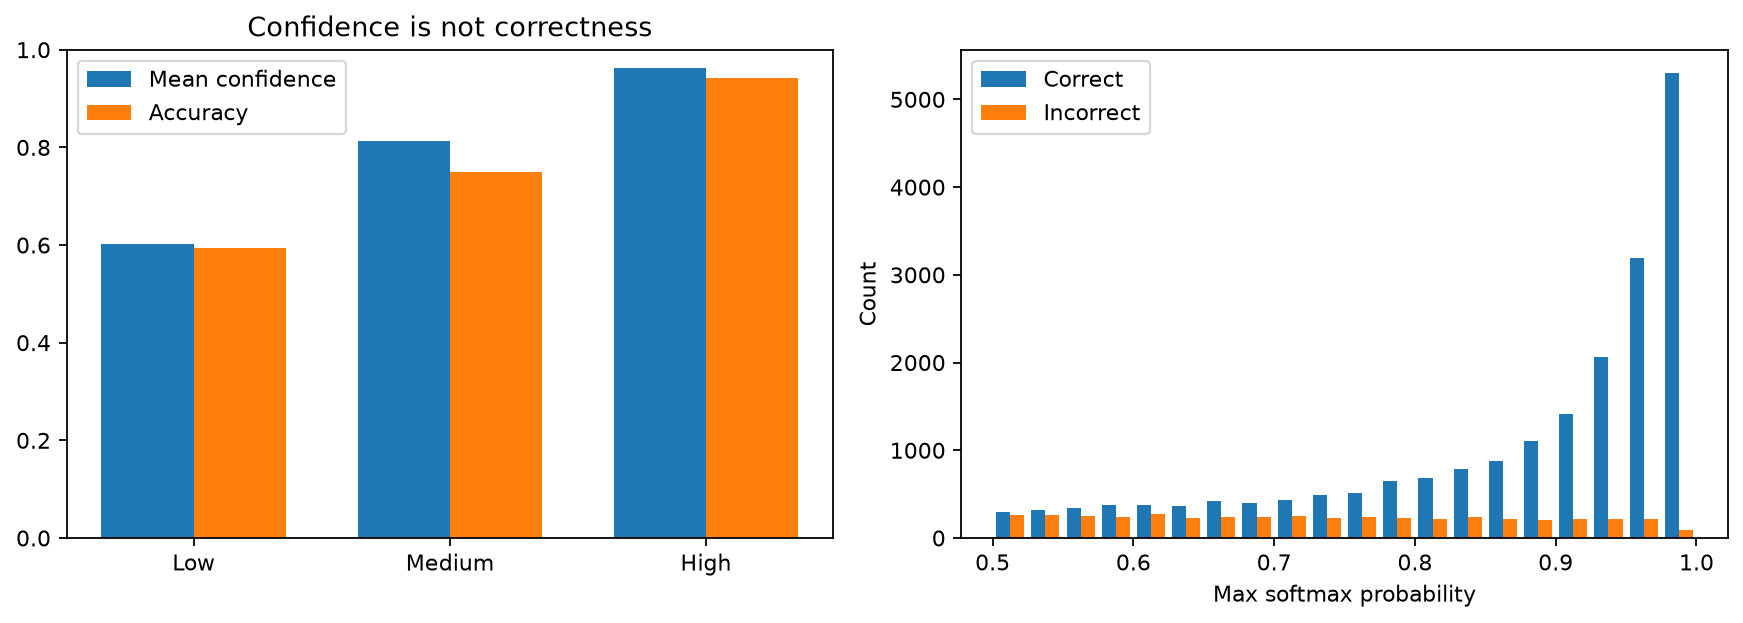

## Application

Pipeline: text -> WordPiece IDs/mask -> contextual CLS -> Linear2 -> softmax. Các câu tự tạo không dùng làm test accuracy.

In [10]:
model,config=load_classifier()
for text in ["I really enjoyed this movie.","This movie is not good.","Great, another two hours of my life wasted."]:
    encoded=tokenizer(text,truncation=True,max_length=config["max_length"],return_tensors="pt")
    with torch.inference_mode(): p=model(**encoded).softmax(-1)[0]
    print(text,"=>",["negative","positive"][p.argmax().item()],"confidence",round(p.max().item(),5))


I really enjoyed this movie. => positive confidence 0.9914
This movie is not good. => positive confidence 0.832
Great, another two hours of my life wasted. => positive confidence 0.96417


## Phần cá nhân và giới hạn

Hoàn thiện error_analysis.md, prediction_verification.md, Q1-Q6 và reflection300-500 từ theo W8. Báo cáo kỹ thuật và số liệu: experiment_report.md. Single seed; cùng LR chưa tối ưu riêng; khác data size đồng thời khác optimizer steps; chưa đo catastrophic forgetting; không suy từ metric thành hiểu ngôn ngữ toàn diện. AI assistance statement ở README.md.